In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
import glob
import os
from scipy.spatial import cKDTree
from itertools import zip_longest
import matplotlib.ticker as ticker

In [2]:
import glob
import matplotlib.font_manager as fm

# Load all CMU fonts
for p in glob.glob("/home1/binhaoli/.local/share/fonts/cmun*.ttf"):
    fm.fontManager.addfont(p)

plt.rcParams["font.family"] = "CMU Sans Serif"
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["axes.unicode_minus"] = False

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
import glob
import os
from scipy.spatial import cKDTree
from itertools import zip_longest
from cmcrameri import cm

def resample_by_arclength(P, ds=1.0):
    """P: Nx2 polyline. Returns roughly uniform-arc-length resampling."""
    seg = np.linalg.norm(np.diff(P, axis=0), axis=1)
    s = np.concatenate(([0.0], np.cumsum(seg)))
    L = s[-1]
    if L == 0:  # degenerate
        return P[[0]].copy()
    s_new = np.arange(0, L + 1e-9, ds)
    # linear interp on cumulative arclength
    Px = np.interp(s_new, s, P[:,0])
    Py = np.interp(s_new, s, P[:,1])
    return np.column_stack([Px, Py])

def directed_nn_distances(A, B):
    """For each point in A, distance to nearest point in B."""
    tree = cKDTree(B)
    d, _ = tree.query(A, k=1, workers=-1)
    return d

def distance_distribution(A, B, ds=1.0):
    """Compute symmetric distribution + standard metrics."""
    Au = resample_by_arclength(A, ds=ds)
    Bu = resample_by_arclength(B, ds=ds)

    dAB = directed_nn_distances(Au, Bu)
    dBA = directed_nn_distances(Bu, Au)
    D = np.concatenate([dAB, dBA])
    
    return D, dAB, dBA

def compute_pdf(D, bins):
    """Return normalized PDF for one realization."""
    pdf, edges = np.histogram(D, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, pdf

def average_histograms(list_of_D, bins):
    """Average PDFs from multiple realizations."""
    all_pdfs = []
    for D in list_of_D:
        # print("len(D):", len(D))
        # print("NaN count:", np.isnan(D).sum())
        # print("min, max:", np.nanmin(D), np.nanmax(D))
        _, pdf = compute_pdf(D, bins)
        all_pdfs.append(pdf)

    all_pdfs = np.vstack(all_pdfs)  # shape (N_MC, N_bins)
    pdf_mean = np.mean(all_pdfs, axis=0)
    pdf_std  = np.std(all_pdfs, axis=0)  # uncertainty band

    centers = 0.5 * (bins[:-1] + bins[1:])
    return centers, pdf_mean, pdf_std

In [4]:
dh = 0.01
K_G = 1 # geometric mean of hydraulic conductivity
I_Y = 0.05 * 200
q_ref = K_G * dh
t_ref = I_Y / q_ref

In [5]:
run = f'2_dh{dh}'
std = [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7, 7.5, 8, 8.5, 9, 9.5, 10]
data = {}
stats = {}
for std_ in std:
    path_base = Path(f'/project2/fbarros_324/binhaoli/task8_rMin_tMin/FastMarchingMethod/run{run}/std_{std_}').expanduser().resolve()
    length_scale = 0.05
    base_pattern = str(path_base / f"lengthScale{length_scale}_size*")
    
    field_size = []
    
    len_fp_sm = []
    len_fp_dijkstra_sm = []
    len_fp_fmm_sm = []
    len_lrp_sm = []
    
    fpt_sm = []
    fpt_dijkstra_sm = []
    fpt_fmm_sm = []
    mhr_sm = []

    hausdorffDist_fp_lrp_sm = []
    hausdorffDist_fp_fpDijkstra_sm = []
    hausdorffDist_fp_fpFMM_sm = []

    endPointDist_fp_lrp_sm = []
    endPointDist_fp_fpDijkstra_sm = []
    endPointDist_fp_fpFMM_sm = []
    
    for path_size in sorted(glob.glob(base_pattern), 
                            key=lambda s: int(s.split("size")[-1])):
        size_str = path_size.split("size")[-1]
        size_val = float(size_str)
        field_size.append(size_val)
    
        path_mainOutputs = sorted(glob.glob(os.path.join(path_size, f"main_output/mainOutput_size{size_str}_mc*.npz")))

        # print(path_mainOutputs)
        if not path_mainOutputs:
            print(f"No files found.")
            continue
    
        # Load all Monte Carlo files for this size
        len_fp_m = []
        len_lrp_m = []
        len_fp_dijkstra_m = []
        len_fp_fmm_m = []
        
        fpt_m = []
        fpt_dijkstra_m = []
        fpt_fmm_m = []
        mhr_m = []

        hausdorffDist_fp_lrp_m = []
        hausdorffDist_fp_fpDijkstra_m = []
        hausdorffDist_fp_fpFMM_m = []

        endPointDist_fp_lrp_m = []
        endPointDist_fp_fpDijkstra_m = []
        endPointDist_fp_fpFMM_m = []
        for f in path_mainOutputs:
            outputData = np.load(f)
            
            len_fp_m.append(outputData['len_fp_m'])
            len_fp_dijkstra_m.append(outputData['len_fp_dijkstra_m'])
            len_fp_fmm_m.append(outputData['len_fp_fmm_m'])
            len_lrp_m.append(outputData['len_lrp_m'])
            
            fpt_m.append(outputData['fpt_m'])
            fpt_dijkstra_m.append(outputData['fpt_dijkstra_m'])
            fpt_fmm_m.append(outputData['fpt_fmm_m'])
            mhr_m.append(outputData['mhr_m'])

            hausdorffDist_fp_lrp_m.append(outputData['hausdorffDist_fp_lrp_m'])
            hausdorffDist_fp_fpDijkstra_m.append(outputData['hausdorffDist_fp_fpDijkstra_m'])
            hausdorffDist_fp_fpFMM_m.append(outputData['hausdorffDist_fp_fpFMM_m'])
    
            endPointDist_fp_lrp_m.append(outputData['endPointDist_fp_lrp_m'])
            endPointDist_fp_fpDijkstra_m.append(outputData['endPointDist_fp_fpDijkstra_m'])
            endPointDist_fp_fpFMM_m.append(outputData['endPointDist_fp_fpFMM_m'])
    
        len_fp_sm.append(np.array(len_fp_m))
        len_fp_dijkstra_sm.append(np.array(len_fp_dijkstra_m))
        len_fp_fmm_sm.append(np.array(len_fp_fmm_m))
        len_lrp_sm.append(np.array(len_lrp_m))
        
        fpt_sm.append(np.array(fpt_m))
        fpt_dijkstra_sm.append(np.array(fpt_dijkstra_m))
        fpt_fmm_sm.append(np.array(fpt_fmm_m))
        mhr_sm.append(np.array(mhr_m))

        hausdorffDist_fp_lrp_sm.append(np.array(hausdorffDist_fp_lrp_m))
        hausdorffDist_fp_fpDijkstra_sm.append(np.array(hausdorffDist_fp_fpDijkstra_m))
        hausdorffDist_fp_fpFMM_sm.append(np.array(hausdorffDist_fp_fpFMM_m))

        endPointDist_fp_lrp_sm.append(np.array(endPointDist_fp_lrp_m))
        endPointDist_fp_fpDijkstra_sm.append(np.array(endPointDist_fp_fpDijkstra_m))
        endPointDist_fp_fpFMM_sm.append(np.array(endPointDist_fp_fpFMM_m))
    
    data[f'std_{std_}'] = {
        'field_size': np.array(field_size),
        
        'len_fp_sm': len_fp_sm,
        'len_fp_dijkstra_sm': len_fp_dijkstra_sm,
        'len_fp_fmm_sm': len_fp_fmm_sm,
        'len_lrp_sm': len_lrp_sm,
        
        'fpt_sm': fpt_sm,
        'fpt_dijkstra_sm': fpt_dijkstra_sm,
        'fpt_fmm_sm': fpt_fmm_sm,
        'mhr_sm': mhr_sm,

        'hausdorffDist_fp_lrp_sm': hausdorffDist_fp_lrp_sm,
        'hausdorffDist_fp_fpDijkstra_sm': hausdorffDist_fp_fpDijkstra_sm,
        'hausdorffDist_fp_fpFMM_sm': hausdorffDist_fp_fpFMM_sm,
        
        'endPointDist_fp_lrp_sm': endPointDist_fp_lrp_sm,
        'endPointDist_fp_fpDijkstra_sm': endPointDist_fp_fpDijkstra_sm,
        'endPointDist_fp_fpFMM_sm': endPointDist_fp_fpFMM_sm
    }

    stats[f'std_{std_}'] = {
        'stats_fp': np.array([(arr.mean(), arr.std()) for arr in len_fp_sm]),
        'stats_fp_dijkstra': np.array([(arr.mean(), arr.std()) for arr in len_fp_dijkstra_sm]),
        'stats_fp_fmm': np.array([(arr.mean(), arr.std()) for arr in len_fp_fmm_sm]),
        'stats_lrp': np.array([(arr.mean(), arr.std()) for arr in len_lrp_sm]),
        
        'stats_fpt': np.array([(arr[arr>0].mean(), arr[arr>0].std()) for arr in fpt_sm]),
        'stats_fpt_dijkstra': np.array([(arr[arr>0].mean(), arr[arr>0].std()) for arr in fpt_dijkstra_sm]),
        'stats_fpt_fmm': np.array([(arr[arr>0].mean(), arr[arr>0].std()) for arr in fpt_fmm_sm]),
        'stats_mhr': np.array([(arr[arr>0].mean(), arr[arr>0].std()) for arr in mhr_sm]),

        'hausdorffDist_fp_lrp': np.array([(arr.mean(), arr.std()) for arr in hausdorffDist_fp_lrp_sm]),
        'hausdorffDist_fp_fpDijkstra': np.array([(arr[arr>0].mean(), arr[arr>0].std()) for arr in hausdorffDist_fp_fpDijkstra_sm]),
        'hausdorffDist_fp_fpFMM': np.array([(arr[arr>0].mean(), arr[arr>0].std()) for arr in hausdorffDist_fp_fpFMM_sm]),
        
        'endPointDist_fp_lrp': np.array([(arr.mean(), arr.std()) for arr in endPointDist_fp_lrp_sm]),
        'endPointDist_fp_fpDijkstra': np.array([(arr.mean(), arr.std()) for arr in endPointDist_fp_fpDijkstra_sm]),
        'endPointDist_fp_fpFMM': np.array([(arr.mean(), arr.std()) for arr in endPointDist_fp_fpFMM_sm]),
        
        # 'stats_fpt': np.array([(arr.mean(), arr.std()) for arr in fpt_sm]),
        # 'stats_fpt_dijkstra': np.array([(arr.mean(), arr.std()) for arr in fpt_dijkstra_sm]),
        # 'stats_fpt_fmm': np.array([(arr.mean(), arr.std()) for arr in fpt_fmm_sm]),
        # 'stats_mhr': np.array([(arr.mean(), arr.std()) for arr in mhr_sm]),
        # 'slope': [],
        # 'std': [],
        # 'R2': []
    }
    
    # for i in range(len(mhr_sm)):
    #     x = mhr_sm[i]
    #     y = fpt_sm[i]
    #     m = np.sum(x * y) / np.sum(x * x)
    #     y_pred = m * x
    #     residuals = y - y_pred
    #     sigma2 = np.sum(residuals**2) / (len(x) - 1)
    #     SE_m = np.sqrt(sigma2 / np.sum(x**2))
    #     R2 = 1 - np.sum(residuals**2) / np.sum(y**2)
    #     stats[f'std_{std_}']['slope'].append(m)
    #     stats[f'std_{std_}']['std'].append(SE_m)
    #     stats[f'std_{std_}']['R2'].append(R2)

In [6]:
std_ = 10
mean = stats[f'std_{std_}']['hausdorffDist_fp_fpFMM'][0,0]
print(mean)

51.481935080060616


In [57]:
arr = np.array(data[f'std_{std_}']['hausdorffDist_fp_fpFMM_sm'][0])
idx = np.where((mean-0.2 < arr) & (arr < mean+0.2))
print(idx)

(array([31]),)


In [58]:
length_scale = 0.05
run = f'2_dh{dh}'
path_size = Path(f'/project2/fbarros_324/binhaoli/task8_rMin_tMin/FastMarchingMethod/run{run}/std_{std}/lengthScale{length_scale}_size200').expanduser().resolve()
sorted(glob.glob(os.path.join(path_size, f"main_output/mainOutput_size{size_str}_mc*.npz")))[idx[0][0]]

'/project2/fbarros_324/binhaoli/task8_rMin_tMin/FastMarchingMethod/run2_dh0.1/std_10/lengthScale0.05_size200/main_output/mainOutput_size200_mc551.npz'

In [59]:
run

'2_dh0.1'

In [7]:
# cmap = cm.batlow_r.resampled(7)
stats_mhr = []
stats_fpt = []
stats_fpt_dijkstra = []
stats_fpt_fmm = []

stats_hausdorffDist_fp_lrp = []
stats_hausdorffDist_fp_fpDijkstra = []
stats_hausdorffDist_fp_fpFMM = []
stats_endPointDist_fp_lrp = []
stats_endPointDist_fp_fpDijkstra = []
stats_endPointDist_fp_fpFMM = []

# stats_slope = []
for i, std_ in enumerate(stats):
    stats_mhr.append(stats[std_]['stats_mhr'][0,:])
    stats_fpt.append(stats[std_]['stats_fpt'][0,:])
    stats_fpt_dijkstra.append(stats[std_]['stats_fpt_dijkstra'][0,:])
    stats_fpt_fmm.append(stats[std_]['stats_fpt_fmm'][0,:])

    stats_hausdorffDist_fp_lrp.append(stats[std_]['hausdorffDist_fp_lrp'][0,:])
    stats_hausdorffDist_fp_fpDijkstra.append(stats[std_]['hausdorffDist_fp_fpDijkstra'][0,:])
    stats_hausdorffDist_fp_fpFMM.append(stats[std_]['hausdorffDist_fp_fpFMM'][0,:])
    stats_endPointDist_fp_lrp.append(stats[std_]['endPointDist_fp_lrp'][0,:])
    stats_endPointDist_fp_fpDijkstra.append(stats[std_]['endPointDist_fp_fpDijkstra'][0,:])
    stats_endPointDist_fp_fpFMM.append(stats[std_]['endPointDist_fp_fpFMM'][0,:])
    # stats_slope.append(stats[std_]['slope'][0])
    
stats_mhr = np.array(stats_mhr)
stats_fpt = np.array(stats_fpt)
stats_fpt_dijkstra = np.array(stats_fpt_dijkstra)
stats_fpt_fmm = np.array(stats_fpt_fmm)
# stats_slope = np.array(stats_slope)

stats_hausdorffDist_fp_lrp = np.array(stats_hausdorffDist_fp_lrp)
stats_hausdorffDist_fp_fpDijkstra = np.array(stats_hausdorffDist_fp_fpDijkstra)
stats_hausdorffDist_fp_fpFMM = np.array(stats_hausdorffDist_fp_fpFMM)
stats_endPointDist_fp_lrp = np.array(stats_endPointDist_fp_lrp)
stats_endPointDist_fp_fpDijkstra = np.array(stats_endPointDist_fp_fpDijkstra)
stats_endPointDist_fp_fpFMM = np.array(stats_endPointDist_fp_fpFMM)

std = np.array(std)
var = std**2

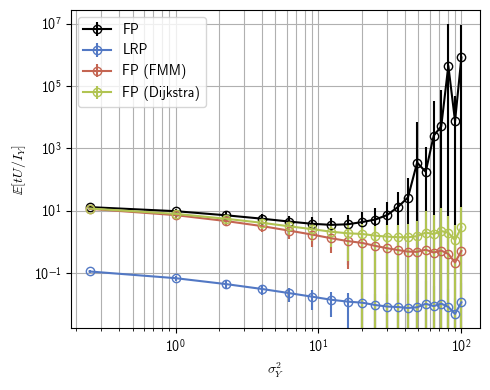

In [8]:
colors = {
    'fp': 'black',
    'lrp': '#5278C4',
    'fpFMM': '#C46552',
    'fpDijkstra': '#B1C452'
}
fig, ax = plt.subplots(figsize=[5,4])
ax.errorbar(var, stats_fpt[:,0]/t_ref, stats_fpt[:,1]/t_ref, color=colors['fp'], linestyle='-', marker='o', markerfacecolor='None', label='FP')
ax.errorbar(var, stats_mhr[:,0]/t_ref, stats_mhr[:,1]/t_ref, color=colors['lrp'], linestyle='-', marker='o', markerfacecolor='None', label='LRP')
ax.errorbar(var, stats_fpt_fmm[:,0]/t_ref, stats_fpt_fmm[:,1]/t_ref, color=colors['fpFMM'], linestyle='-', marker='o', markerfacecolor='None', label='FP (FMM)')
ax.errorbar(var, stats_fpt_dijkstra[:,0]/t_ref, stats_fpt_dijkstra[:,1]/t_ref, color=colors['fpDijkstra'], linestyle='-', marker='o', markerfacecolor='None', label='FP (Dijkstra)')
ax.set_xscale('log')  # log scale for x-axis
ax.set_yscale('log')  # log scale for y-axis
# ax.set_ylim([10**1.1, 10**19.5])
ax.set_xlabel('$\\sigma_{Y}^2$')
ax.set_ylabel(r'$\mathbb{E}\left[ tU / I_Y \right]$')
# ax.set_title(f'Variation of Characteristic Time with Variance (dh={dh})')
ax.legend()
plt.grid(True, which='both')
fig.tight_layout()
fig.savefig(f"charTime_dh{dh}.png", dpi=400, bbox_inches="tight")
plt.show()

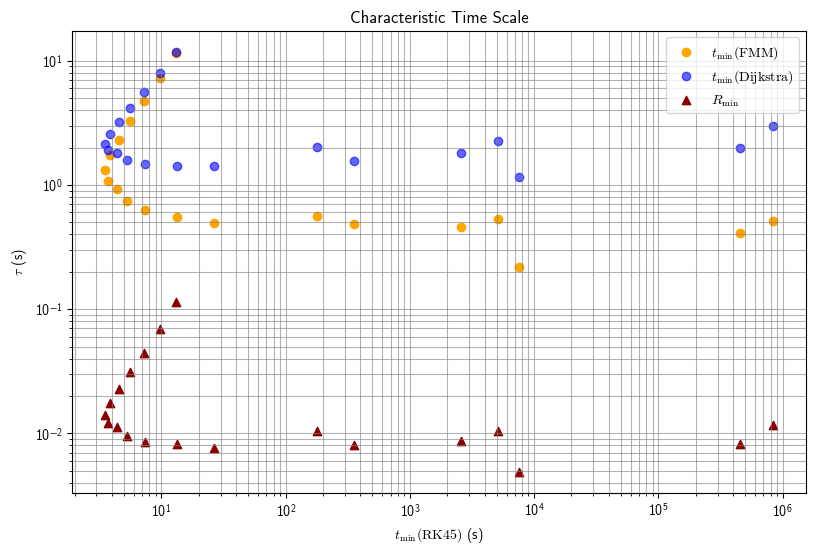

In [9]:
fig, ax = plt.subplots(figsize=(10,6))
ax.scatter(stats_fpt[:,0]/t_ref, stats_fpt_fmm[:,0]/t_ref, color='orange', label='$t_{\\text{min}}\\text{(FMM)}$', alpha=1)
ax.scatter(stats_fpt[:,0]/t_ref, stats_fpt_dijkstra[:,0]/t_ref, color='blue', label='$t_{\\text{min}}\\text{(Dijkstra)}$', alpha=0.6)
ax.scatter(stats_fpt[:,0]/t_ref, stats_mhr[:,0]/t_ref, color='darkred', marker='^', label='$R_{\\text{min}}$', alpha=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("$t_{\\text{min}}\\text{(RK45)}$ (s)")
ax.set_ylabel("$\\tau$ (s)")
ax.grid(True, which='both', color='gray', linestyle='-', linewidth=0.8, alpha=0.6)
ax.set_aspect('equal', adjustable='box')
ax.set_title("Characteristic Time Scale")
ax.legend()

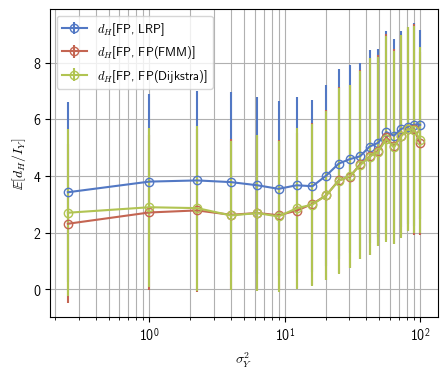

In [98]:
fig, ax = plt.subplots(figsize=[5, 4])
x = np.array(std)**2

dist_st = field_size[0] - 2*field_size[0]//20

y_fp_lrp = stats_hausdorffDist_fp_lrp[:,0] / I_Y
yerr_fp_lrp = stats_hausdorffDist_fp_lrp[:,1] / I_Y
ax.errorbar(x, y_fp_lrp, yerr=yerr_fp_lrp, label='$d_H$[FP, LRP]', linestyle='-', color=colors['lrp'], marker='o', markerfacecolor='None')

y_fp_fpFMM = stats_hausdorffDist_fp_fpFMM[:,0] / I_Y
yerr_fp_fpFMM = stats_hausdorffDist_fp_fpFMM[:,1] / I_Y
ax.errorbar(x, y_fp_fpFMM, yerr=yerr_fp_fpFMM, label='$d_H$[FP, FP(FMM)]', linestyle='-', color=colors['fpFMM'], marker='o', markerfacecolor='None')

y_fp_fpDijkstra = stats_hausdorffDist_fp_fpDijkstra[:,0] / I_Y
yerr_fp_fpDijkstra = stats_hausdorffDist_fp_fpDijkstra[:,1] / I_Y
ax.errorbar(x, y_fp_fpDijkstra, yerr=yerr_fp_fpDijkstra, label='$d_H$[FP, FP(Dijkstra)]', linestyle='-', color=colors['fpDijkstra'], marker='o', markerfacecolor='None')

ax.set_xscale('log') 
ax.set_xlabel('$\\sigma_{Y}^2$')
ax.set_ylabel(r'$\mathbb{E}\left[ d_H / I_Y \right]$')
# ax.set_ylim([0, 0.5])
# ax.set_title(f'Variation of Hausdorff Distance with Variance (dh={dh})')
ax.legend(fontsize='9', loc='upper left')
plt.grid(True, which='both')
# fig.tight_layout()
fig.savefig(f"hausdorffDist_dh{dh}.png", dpi=400, bbox_inches="tight")
plt.show()

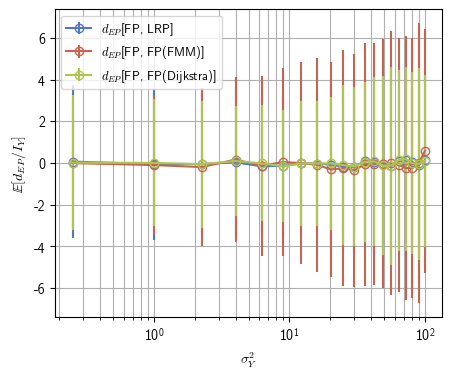

In [99]:
fig, ax = plt.subplots(figsize=[5, 4])
x = np.array(std)**2

dist_st = field_size[0] - 2*field_size[0]//20

y_fp_lrp = stats_endPointDist_fp_lrp[:,0] / I_Y
yerr_fp_lrp = stats_endPointDist_fp_lrp[:,1] / I_Y
ax.errorbar(x, y_fp_lrp, yerr=yerr_fp_lrp, label='$d_{EP}$[FP, LRP]', linestyle='-', color=colors['lrp'], marker='o', markerfacecolor='None')

y_fp_fpFMM = stats_endPointDist_fp_fpFMM[:,0] / I_Y
yerr_fp_fpFMM = stats_endPointDist_fp_fpFMM[:,1] / I_Y
ax.errorbar(x, y_fp_fpFMM, yerr=yerr_fp_fpFMM, label='$d_{EP}$[FP, FP(FMM)]', linestyle='-', color=colors['fpFMM'], marker='o', markerfacecolor='None')

y_fp_fpDijkstra = stats_endPointDist_fp_fpDijkstra[:,0] / I_Y
yerr_fp_fpDijkstra = stats_endPointDist_fp_fpDijkstra[:,1] / I_Y
ax.errorbar(x, y_fp_fpDijkstra, yerr=yerr_fp_fpDijkstra, label='$d_{EP}$[FP, FP(Dijkstra)]', linestyle='-', color=colors['fpDijkstra'], marker='o', markerfacecolor='None')

ax.set_xscale('log') 
ax.set_xlabel('$\\sigma_{Y}^2$')
ax.set_ylabel(r'$\mathbb{E}\left[ d_{EP} / I_Y \right]$')
# ax.set_ylim([0, 0.5])
# ax.set_title(f'Variation of Hausdorff Distance with Variance (dh={dh})')
ax.legend(fontsize='9', loc='upper left')
plt.grid(True, which='both')
# fig.tight_layout()
fig.savefig(f"endPointDist_dh{dh}.png", dpi=400, bbox_inches="tight")
plt.show()

In [20]:
import numpy as np

# --- 1. DATA PREPARATION ---
# Estimated points for the first (shallow) part
x1 = var[0:6]
y1 = stats_slope[0:6]

# Estimated points for the second (steep) part
x2 = var[10:16]
y2 = stats_slope[10:16]

def sign(x):
    if x >= 0:
        return '+'
    else:
        return '-'
        
def estimate_log_slope(x, y):
    """
    Performs linear regression on log-transformed data.
    The slope of log(y) vs log(x) is the power-law exponent.
    """
    log_x = np.log10(x)
    log_y = np.log10(y)
    
    # polyfit returns [slope, intercept]
    slope, intercept = np.polyfit(log_x, log_y, 1)
    return slope, intercept

# --- 2. CALCULATION ---
slope1, intercept1 = estimate_log_slope(x1, y1)
slope2, intercept2 = estimate_log_slope(x2, y2)

print(f"Estimated Slope (Shallow Part): {slope1:.3f}")
print(f"Estimated Slope (Steep Part):   {slope2:.3f}")

Estimated Slope (Shallow Part): 0.178
Estimated Slope (Steep Part):   nan


/tmp/SLURM_6020481/ipykernel_2301579/127337558.py:24: RuntimeWarning: invalid value encountered in log10
  log_y = np.log10(y)


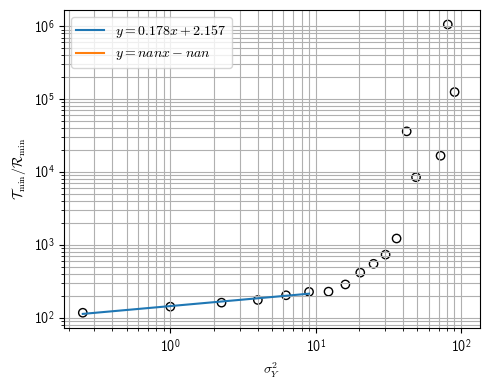

In [21]:
fig, ax = plt.subplots(figsize=[5,4])
cmap = cm.batlow_r.resampled(7)
# ax.plot(var, stats_slope, color='black', marker='o', markerfacecolor='None')
ax.scatter(var, stats_slope, color='black', marker='o', facecolor='None')
ax.plot(x1, 10**intercept1 * x1**slope1, '-', label='$y='+f'{slope1:.3f}'+'x'+sign(intercept1)+f'{np.abs(intercept1):.3f}$')
ax.plot(x2, 10**intercept2 * x2**slope2, '-', label='$y='+f'{slope2:.3f}'+'x'+sign(intercept2)+f'{np.abs(intercept2):.3f}$')
ax.set_xscale('log')  # log scale for x-axis
ax.set_yscale('log')  # log scale for y-axis
# ax.set_ylim([10**1.96, 10**3.4])
# ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%g'))
# ax.yaxis.set_minor_formatter(ticker.LogFormatterSciNotation(labelOnlyBase=True))
ax.set_xlabel('$\\sigma_{Y}^2$')
ax.set_ylabel('$\\mathcal{T}_{\\text{min}}/\\mathcal{R}_{\\text{min}}$')
# ax.set_title('Variation of Characteristic Time Ratio with Field Size')
ax.legend()
plt.grid(True, which='both')
fig.tight_layout()
fig.savefig(f"charTimeRatio_variation.png", dpi=400, bbox_inches="tight")
plt.show()

Fitted Equation: y = 174.03 * e^(0.0635 * x) + -363.48


<>:34: SyntaxWarning: invalid escape sequence '\s'
<>:34: SyntaxWarning: invalid escape sequence '\s'
/tmp/SLURM_5481585/ipykernel_477684/1064455534.py:34: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('$\sigma_Y^2$')


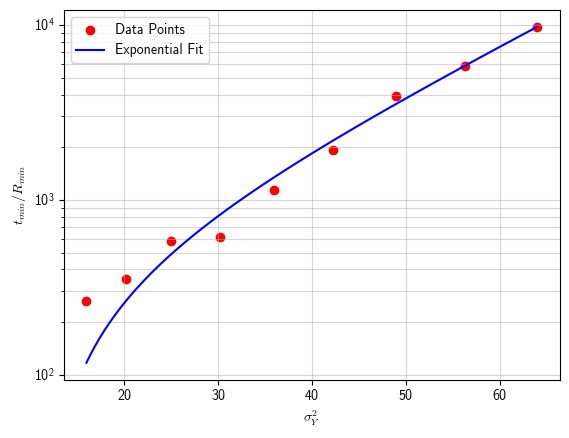

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. Define the exponential model function
def exponential_model(x, a, b, c):
    """y = a * exp(b * x) + c"""
    return a * np.exp(b * x) + c

# 2. Your Data (using estimates from your plot for the steep part)
# Replace these with your actual extracted values

x_data = np.array(var[7:16])
y_data = np.array(stats_slope[7:16])

# 3. Perform the fit
# 'p0' is the initial guess for [a, b, c]. 
# For exponential growth, b should be small and positive.
initial_guess = [1, 0.1, 100]

popt, pcov = curve_fit(exponential_model, x_data, y_data, p0=initial_guess)

# 4. Extract parameters
a_opt, b_opt, c_opt = popt
print(f"Fitted Equation: y = {a_opt:.2f} * e^({b_opt:.4f} * x) + {c_opt:.2f}")

# 5. Visualize the result
x_fit = np.linspace(min(x_data), max(x_data), 100)
y_fit = exponential_model(x_fit, *popt)

plt.scatter(x_data, y_data, label='Data Points', color='red')
plt.plot(x_fit, y_fit, label='Exponential Fit', color='blue')
plt.yscale('log') # Match the log scale of your original image
plt.xlabel('$\sigma_Y^2$')
plt.ylabel('$t_{min}/R_{min}$')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

In [35]:
np.sign(intercept1)

np.float64(1.0)

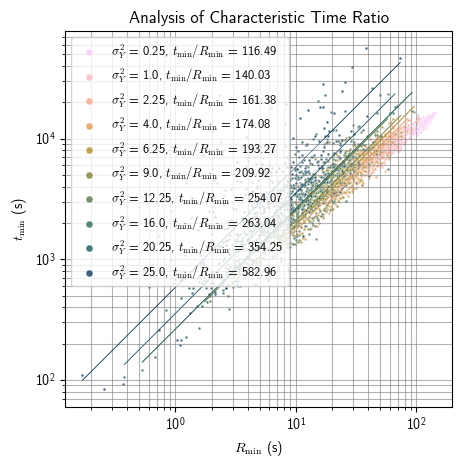

In [19]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import cmcrameri.cm as cm
import matplotlib.ticker as ticker

fig, ax = plt.subplots(figsize=(5,5))
cmap = cm.batlow_r.resampled(len(std)+1)
for i, std_ in enumerate(data):
    y = np.array(data[std_]['fpt_sm'][0])
    x = np.array(data[std_]['mhr_sm'][0])
    k = np.sum(x * y) / np.sum(x**2)
    ax.plot(x, k * x, linestyle='-', color=cmap(i), linewidth=0.5, alpha=0.8, zorder=2)
    ax.scatter(x, y, label=f"$\\sigma_{{Y}}^2$ = {var[i]}, "+"$t_{\\text{min}}/R_{\\text{min}}$ = "+f"{k:.2f}", color=cmap(i), alpha=0.8, s=4, edgecolors='white', linewidths=0.3, zorder=1)

# ax_inset = inset_axes(ax, width="35%", height="35%", loc=4, borderpad=2)
# x1, x2, y1, y2 = 10**(-0.3), 10**0.3, 10**(2.2), 10**2.8 # 10**2.25, 10**2.75
# ax_inset.set_xlim([x1, x2])
# ax_inset.set_ylim([y1, y2])
# for i, std_ in enumerate(data):
#     y = np.array(data[std_]['fpt_sm'])
#     x = np.array(data[std_]['mhr_sm'])
#     k = np.sum(x * y) / np.sum(x**2)
#     ax.plot(x, k * x, linestyle='-', color=cmap(i), linewidth=0.5, alpha=0.8, zorder=2)
#     ax.scatter(x, y, color=cmap(i), alpha=0.8, s=4, edgecolors='white', linewidths=0.3, zorder=1)

# ax_inset.set_xscale('log')  
# ax_inset.set_yscale('log') 
# ax_inset.xaxis.set_minor_formatter(ticker.NullFormatter())
# ax_inset.yaxis.set_minor_formatter(ticker.NullFormatter())
# ax_inset.set_aspect('equal', adjustable='box')

# mark_inset(ax, ax_inset, loc1=1, loc2=3, fc="none", ls="--", alpha=1, color='black', zorder=3)
# # mark_inset(ax, ax_inset, loc1=3, loc2=4, fc="none", ls="--", alpha=0.4, color='black', zorder=1)

ax.legend(
    markerscale=2.5,
    fontsize='9',
    loc='upper left'
)
ax.set_xscale('log')  
ax.set_yscale('log') 
ax.set_xlabel('$R_{\\text{min}}$ (s)')
ax.set_ylabel('$t_{\\text{min}}$ (s)')
ax.set_title('Analysis of Characteristic Time Ratio')
ax.grid(True, which='both', color='gray', linestyle='-', linewidth=0.8, alpha=0.6)
ax.set_aspect('equal', adjustable='box')

# fig.tight_layout()
# fig.savefig(f"charTimeRatio_scatter.png", dpi=400, bbox_inches="tight")
plt.show()

## Load all paths

In [18]:
length_scale = 0.05
std = [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7, 7.5, 8, 8.5, 9, 9.5, 10]

data_path = {}
for std_ in std:
    path_base = Path(f'/project2/fbarros_324/binhaoli/task8_rMin_tMin/FastMarchingMethod/run{run}/std_{std_}').expanduser().resolve()
    base_pattern = str(path_base / f"lengthScale{length_scale}_size*")
    
    # End point distance
    field_size = []
    histDist_fp_lrp_sm = []
    hausdorffDist_fp_lrp_sm = []
    endPointDist_fp_lrp_sm = []
    
    histDist_fp_fpDijkstra_sm = []
    hausdorffDist_fp_fpDijkstra_sm = []
    endPointDist_fp_fpDijkstra_sm = []
    
    histDist_fp_fpFMM_sm = []
    hausdorffDist_fp_fpFMM_sm = []
    endPointDist_fp_fpFMM_sm = []
    for size_dir in sorted(glob.glob(base_pattern), key=lambda s: int(s.split("size")[-1])):
        # Go to folders for sizes
        size_str = size_dir.split("size")[-1]
        size_val = float(size_str)
        field_size.append(size_val)
        x_cp = size_val - size_val//20 - 1
    
        fp_files = sorted(glob.glob(os.path.join(size_dir, f"path/fp_size{size_str}_mc*.npy")))
        lrp_files = sorted(glob.glob(os.path.join(size_dir, f"path/lrp_size{size_str}_mc*.npy")))
        fpDijkstra_files = sorted(glob.glob(os.path.join(size_dir, f"path/fp_dijkstra_size{size_str}_mc*.npy")))
        fpFMM_files = sorted(glob.glob(os.path.join(size_dir, f"path/fp_fmm_size{size_str}_mc*.npy")))
    
        if not (fp_files or lrp_files or fpDijkstra_files or fpFMM_files):
            print(f"No path files found in {len_path}")
            continue
    
        # Load all Monte Carlo files for this size
        histDist_fp_lrp_m = []
        hausdorffDist_fp_lrp_m = []
        endPointDist_fp_lrp_m = []
        
        histDist_fp_fpDijkstra_m = []
        hausdorffDist_fp_fpDijkstra_m = []
        endPointDist_fp_fpDijkstra_m = []
        
        histDist_fp_fpFMM_m = []
        hausdorffDist_fp_fpFMM_m = []
        endPointDist_fp_fpFMM_m = []
        for fp_file, lrp_file, fpDijkstra_file, fpFMM_file in zip_longest(fp_files, lrp_files, fpDijkstra_files, fpFMM_files):
            if fp_file is not None:
                fp = np.load(fp_file)
        
            if lrp_file is not None:
                lrp = np.load(lrp_file)

            if fpDijkstra_file is not None:
                fpDijkstra = np.load(fpDijkstra_file)

            if fpFMM_file is not None:
                fpFMM = np.load(fpFMM_file)
    
            # Compare FP and LRP
            histDist_fp_lrp, _, _ = distance_distribution(fp, lrp, ds=1.0)
            histDist_fp_lrp_m.append(histDist_fp_lrp)
            hausdorffDist_fp_lrp_m.append(max(histDist_fp_lrp))
            endPointDist_fp_lrp_m.append(fp[-1,1] - lrp[-1,1])

            # Compare FP and FP (Dijkstra)
            histDist_fp_fpDijkstra, _, _ = distance_distribution(fp, fpDijkstra, ds=1.0)
            histDist_fp_fpDijkstra_m.append(histDist_fp_fpDijkstra)
            hausdorffDist_fp_fpDijkstra_m.append(max(histDist_fp_fpDijkstra))
            endPointDist_fp_fpDijkstra_m.append(fp[-1,1] - fpDijkstra[-1,1])

            # Compare FP and FP (FMM)
            histDist_fp_fpFMM, _, _ = distance_distribution(fp, fpFMM, ds=1.0)
            histDist_fp_fpFMM_m.append(histDist_fp_fpFMM)
            hausdorffDist_fp_fpFMM_m.append(max(histDist_fp_fpFMM))
            endPointDist_fp_fpFMM_m.append(fp[-1,1] - fpFMM[-1,1])
    
        histDist_fp_lrp_sm.append(histDist_fp_lrp_m)
        hausdorffDist_fp_lrp_sm.append(hausdorffDist_fp_lrp_m)
        endPointDist_fp_lrp_sm.append(endPointDist_fp_lrp_m)

        histDist_fp_fpDijkstra_sm.append(histDist_fp_fpDijkstra_m)
        hausdorffDist_fp_fpDijkstra_sm.append(hausdorffDist_fp_fpDijkstra_m)
        endPointDist_fp_fpDijkstra_sm.append(endPointDist_fp_fpDijkstra_m)

        histDist_fp_fpFMM_sm.append(histDist_fp_fpFMM_m)
        hausdorffDist_fp_fpFMM_sm.append(hausdorffDist_fp_fpFMM_m)
        endPointDist_fp_fpFMM_sm.append(endPointDist_fp_fpFMM_m)

    data_path[f'std_{std_}'] = {
        'field_size': field_size,
        
        'histDist_fp_lrp_sm': histDist_fp_lrp_sm,
        'hausdorffDist_fp_lrp_sm': hausdorffDist_fp_lrp_sm,
        'endPointDist_fp_lrp_sm': endPointDist_fp_lrp_sm,

        'histDist_fp_fpDijkstra_sm': histDist_fp_fpDijkstra_sm,
        'hausdorffDist_fp_fpDijkstra_sm': hausdorffDist_fp_fpDijkstra_sm,
        'endPointDist_fp_fpDijkstra_sm': endPointDist_fp_fpDijkstra_sm,

        'histDist_fp_fpFMM_sm': histDist_fp_fpFMM_sm,
        'hausdorffDist_fp_fpFMM_sm': hausdorffDist_fp_fpFMM_sm,
        'endPointDist_fp_fpFMM_sm': endPointDist_fp_fpFMM_sm
    }

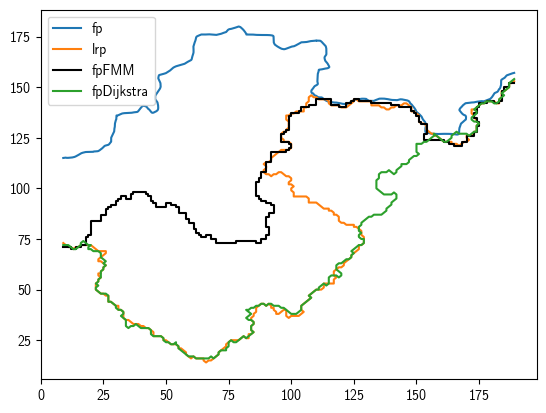

In [19]:
plt.plot(fp[:,0], fp[:,1], label='fp')
plt.plot(lrp[:,0], lrp[:,1], label='lrp')
plt.plot(fpFMM[:,0], fpFMM[:,1], label='fpFMM', color='black')
plt.plot(fpDijkstra[:,0], fpDijkstra[:,1], label='fpDijkstra')
plt.legend()

In [20]:
stats_path = {}

for key_c in data_path:
    stats_path[key_c] = {}
    for key_ in data_path[key_c]:
        if (key_ != 'histDist_fp_lrp_sm') and (key_ != 'histDist_fp_fpDijkstra_sm') and (key_ != 'histDist_fp_fpFMM_sm'):
            # print(key_c, key_)
            means = [np.mean(lst) for lst in data_path[key_c][key_]]
            stds = [np.std(lst) for lst in data_path[key_c][key_]]
            stats_path[key_c][key_] = [means, stds]

In [21]:
statsPath_std = {
    'hausdorffDist': {
        'fp_lrp': [],
        'fp_fpDijkstra': [],
        'fp_fpFMM': []
    },
    'endPointDist': {
        'fp_lrp': [],
        'fp_fpDijkstra': [],
        'fp_fpFMM': []
    }
}
for i, std_ in enumerate(stats_path):
    statsPath_std['hausdorffDist']['fp_lrp'].append(stats_path[std_]['hausdorffDist_fp_lrp_sm'])
    statsPath_std['hausdorffDist']['fp_fpDijkstra'].append(stats_path[std_]['hausdorffDist_fp_fpDijkstra_sm'])
    statsPath_std['hausdorffDist']['fp_fpFMM'].append(stats_path[std_]['hausdorffDist_fp_fpFMM_sm'])
    
    statsPath_std['endPointDist']['fp_lrp'].append(stats_path[std_]['endPointDist_fp_lrp_sm'])
    statsPath_std['endPointDist']['fp_fpDijkstra'].append(stats_path[std_]['endPointDist_fp_fpDijkstra_sm'])
    statsPath_std['endPointDist']['fp_fpFMM'].append(stats_path[std_]['endPointDist_fp_fpFMM_sm'])

for key1 in statsPath_std:
    for key2 in statsPath_std[key1]:
        statsPath_std[key1][key2] = np.array(statsPath_std[key1][key2])


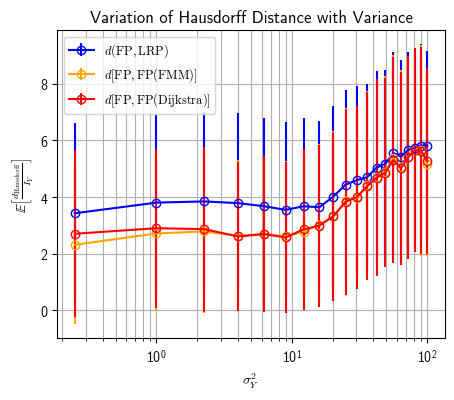

In [23]:
fig, ax = plt.subplots(figsize=[5, 4])
# args_plot = {
#     'label': ['$c$ = 0.1', '$c$ = 1', '$c$ = 3'],
#     'linestyle': ['-', '--', ':']
# }
colors = cm.batlow_r.resampled(len(std)+1)
x = np.array(std)**2

dist_st = field_size[0] - 2*field_size[0]//20

y_fp_lrp = np.array(statsPath_std['hausdorffDist']['fp_lrp'][:,0,0]) / I_Y
yerr_fp_lrp = np.array(statsPath_std['hausdorffDist']['fp_lrp'][:,1,0]) / I_Y
ax.errorbar(x, y_fp_lrp, yerr=yerr_fp_lrp, label='$d(\\text{FP}, \\text{LRP})$', linestyle='-', color='blue', marker='o', markerfacecolor='None')

y_fp_fpFMM = np.array(statsPath_std['hausdorffDist']['fp_fpFMM'][:,0,0]) / I_Y
yerr_fp_fpFMM = np.array(statsPath_std['hausdorffDist']['fp_fpFMM'][:,1,0]) / I_Y
ax.errorbar(x, y_fp_fpFMM, yerr=yerr_fp_fpFMM, label='$d[\\text{FP}, \\text{FP(FMM)}]$', linestyle='-', color='orange', marker='o', markerfacecolor='None')

y_fp_fpDijkstra = np.array(statsPath_std['hausdorffDist']['fp_fpDijkstra'][:,0,0]) / I_Y
yerr_fp_fpDijkstra = np.array(statsPath_std['hausdorffDist']['fp_fpDijkstra'][:,1,0]) / I_Y
ax.errorbar(x, y_fp_fpDijkstra, yerr=yerr_fp_fpDijkstra, label='$d[\\text{FP}, \\text{FP(Dijkstra)}]$', linestyle='-', color='red', marker='o', markerfacecolor='None')

ax.set_xscale('log') 
ax.set_xlabel('$\\sigma_{Y}^2$')
ax.set_ylabel('$\\mathbb{E}\\left[ \\frac{d_{\\text{Hausdorff}}}{I_Y} \\right]$')
# ax.set_ylim([0, 0.5])
ax.set_title('Variation of Hausdorff Distance with Variance')
ax.legend(fontsize='9', loc='upper left')
plt.grid(True, which='both')
# fig.tight_layout()
# fig.savefig(f"hausdorffDist_variation.png", dpi=400, bbox_inches="tight")
plt.show()

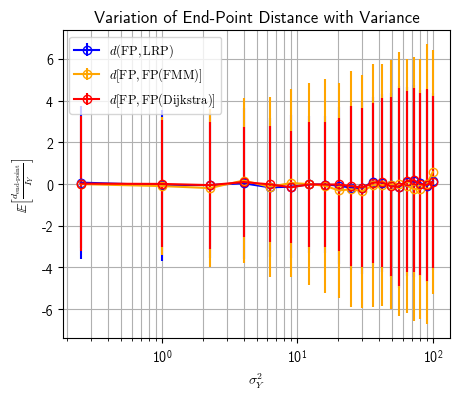

In [24]:
fig, ax = plt.subplots(figsize=[5, 4])
# args_plot = {
#     'label': ['$c$ = 0.1', '$c$ = 1', '$c$ = 3'],
#     'linestyle': ['-', '--', ':']
# }
colors = cm.batlow_r.resampled(len(std)+1)
x = np.array(std)**2

dist_st = field_size[0] - 2*field_size[0]//20

y_fp_lrp = np.array(statsPath_std['endPointDist']['fp_lrp'][:,0,0]) / I_Y
yerr_fp_lrp = np.array(statsPath_std['endPointDist']['fp_lrp'][:,1,0]) / I_Y
ax.errorbar(x, y_fp_lrp, yerr=yerr_fp_lrp, label='$d(\\text{FP}, \\text{LRP})$', linestyle='-', color='blue', marker='o', markerfacecolor='None')

y_fp_fpFMM = np.array(statsPath_std['endPointDist']['fp_fpFMM'][:,0,0]) / I_Y
yerr_fp_fpFMM = np.array(statsPath_std['endPointDist']['fp_fpFMM'][:,1,0]) / I_Y
ax.errorbar(x, y_fp_fpFMM, yerr=yerr_fp_fpFMM, label='$d[\\text{FP}, \\text{FP(FMM)}]$', linestyle='-', color='orange', marker='o', markerfacecolor='None')

y_fp_fpDijkstra = np.array(statsPath_std['endPointDist']['fp_fpDijkstra'][:,0,0]) / I_Y
yerr_fp_fpDijkstra = np.array(statsPath_std['endPointDist']['fp_fpDijkstra'][:,1,0]) / I_Y
ax.errorbar(x, y_fp_fpDijkstra, yerr=yerr_fp_fpDijkstra, label='$d[\\text{FP}, \\text{FP(Dijkstra)}]$', linestyle='-', color='red', marker='o', markerfacecolor='None')

ax.set_xscale('log') 
ax.set_xlabel('$\\sigma_{Y}^2$')
ax.set_ylabel('$\\mathbb{E}\\left[ \\frac{d_{\\text{end-point}}}{I_Y} \\right]$')
# ax.set_ylim([0, 0.5])
ax.set_title('Variation of End-Point Distance with Variance')
ax.legend(fontsize='9', loc='upper left')
plt.grid(True, which='both')
# fig.tight_layout()
# fig.savefig(f"hausdorffDist_variation.png", dpi=400, bbox_inches="tight")
plt.show()